# Group Deliverable — Comparison of All Six Models
**Group ID:** 2026-Y2-S1-MLB-B11G2-05 &nbsp;|&nbsp; **Module:** IT2011 Artificial Intelligence and Machine Learning

This notebook combines the tuned best result from each of the six individual member notebooks.

| Member | Index No. | Model | Type |
|---|---|---|---|
| Nirushiya A. | IT25100513 | Support Vector Machine | Classification |
| Thrishodaran V. | IT25102227 | Decision Tree | Classification |
| Wijayagunasekara L.A.V.D.S. | IT25100064 | Logistic Regression | Classification |
| Almeida K.K.O. | IT25103191 | K-Means | Clustering |
| Danishiyan G.J. | IT25101436 | Principal Component Analysis (PCA, 13 components) → KNN | Dimensionality Reduction + Classification (KNN) |
| Muhunthan R. | IT25102618 | Multi-Layer Perceptron | Deep Learning |

Each member's notebook writes its own tuned results to `results/model_metrics/*.json`; this notebook
reads those files rather than recomputing, so the comparison always reflects each member's actual
final model. All six models were built on the same processed dataset (18,668 rows, 21 standardised
features) and the four classifiers share an identical 80/20 stratified split with `random_state=42`,
making their metrics directly comparable.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

names = ['svm', 'tree', 'logreg', 'kmeans', 'pca', 'mlp']
R = {}
for n in names:
    with open(f'../results/model_metrics/{n}_results.json') as f:
        R[n] = json.load(f)
svm, tree, logreg, kmeans, pca, mlp = (R[n] for n in names)
print("All 6 member result files loaded:")
for n in names:
    print(f"  {n:7s} -> {R[n]['member']}  |  {R[n]['model_family']}")


All 6 member result files loaded:
  svm     -> Nirushiya A. (IT25100513)  |  Support Vector Machine (Classification)
  tree    -> Thrishodaran V. (IT25102227)  |  Decision Tree (Classification)
  logreg  -> Wijayagunasekara L.A.V.D.S. (IT25100064)  |  Logistic Regression (Classification)
  kmeans  -> Almeida K.K.O. (IT25103191)  |  K-Means (Clustering)
  pca     -> Danishiyan G.J. (IT25101436)  |  PCA (Dimensionality Reduction)
  mlp     -> Muhunthan R. (IT25102618)  |  Multi-Layer Perceptron (Deep Learning)


## 1. Classification Models Head-to-Head

The SVM, Decision Tree, Logistic Regression and MLP all solve the *same* 26-class letter
classification task on the *same* split, so accuracy, precision, recall and F1 are directly
comparable between them.

Danishiyan's **PCA (13 components) → KNN** pipeline also classifies letters on the same split, so it
is included in this head-to-head as well. Its metrics are those of the full pipeline — PCA reduces
the 21 features to 13 components, then KNN classifies them — not of PCA on its own.

In [2]:
rows = []
for res in [svm, tree, logreg, mlp]:
    rows.append({
        'Model': res['model_family'].split(' (')[0],
        'Member': res['member'].split(' (')[0],
        'Accuracy': res['accuracy'],
        'Precision (macro)': res['precision_macro'],
        'Recall (macro)': res['recall_macro'],
        'F1 (macro)': res['f1_macro'],
        'Best hyperparameters': str(res['best_params']),
    })
# The four stand-alone classifiers (used for the analysis in later sections)
comparison_df = (pd.DataFrame(rows)
                 .sort_values('Accuracy', ascending=False)
                 .reset_index(drop=True))

# Head-to-head table: the four classifiers plus the PCA -> KNN classification pipeline
pca_knn_row = {
    'Model': f"PCA ({pca['n_components_chosen']} components) \u2192 KNN",
    'Member': pca['member'].split(' (')[0],
    'Accuracy': pca['knn_accuracy_pca_features'],
    'Precision (macro)': pca['knn_precision_macro_pca_features'],
    'Recall (macro)': pca['knn_recall_macro_pca_features'],
    'F1 (macro)': pca['knn_f1_macro_pca_features'],
    'Best hyperparameters': f"{{'n_components': {pca['n_components_chosen']}, 'knn_n_neighbors': 5}}",
}
head_to_head = (pd.concat([comparison_df, pd.DataFrame([pca_knn_row])], ignore_index=True)
                .sort_values('Accuracy', ascending=False)
                .reset_index(drop=True))

print(head_to_head.drop(columns=['Best hyperparameters']).round(4).to_string(index=False))
print()
for _, r in head_to_head.iterrows():
    print(f"{r['Model']}: {r['Best hyperparameters']}")
head_to_head


                    Model                      Member  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)
   Support Vector Machine                Nirushiya A.    0.9646             0.9654          0.9645      0.9648
   Multi-Layer Perceptron                Muhunthan R.    0.9467             0.9476          0.9457      0.9464
PCA (13 components) → KNN             Danishiyan G.J.    0.9033             0.9064          0.9028      0.9037
            Decision Tree             Thrishodaran V.    0.8605             0.8615          0.8606      0.8607
      Logistic Regression Wijayagunasekara L.A.V.D.S.    0.7732             0.7773          0.7720      0.7730

Support Vector Machine: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Multi-Layer Perceptron: {'activation': 'tanh', 'alpha': 0.001, 'hidden_layer_sizes': [128, 64]}
PCA (13 components) → KNN: {'n_components': 13, 'knn_n_neighbors': 5}
Decision Tree: {'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split

,Model,Member,Accuracy,Precision (macro),Recall (macro),F1 (macro),Best hyperparameters
0,Support Vector Machine,Nirushiya A.,0.964649,0.965403,0.964488,0.964816,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}"
1,Multi-Layer Perceptron,Muhunthan R.,0.946706,0.947576,0.945680,0.946356,"{'activation': 'tanh', 'alpha': 0.001, 'hidden..."
2,PCA (13 components) → KNN,Danishiyan G.J.,0.903321,0.906410,0.902779,0.903726,"{'n_components': 13, 'knn_n_neighbors': 5}"
3,Decision Tree,Thrishodaran V.,0.860471,0.861538,0.860625,0.860684,"{'criterion': 'entropy', 'max_depth': 20, 'min..."
4,Logistic Regression,Wijayagunasekara L.A.V.D.S.,0.773166,0.777277,0.771957,0.772973,"{'C': 1, 'max_iter': 1000, 'penalty': 'l1', 's..."


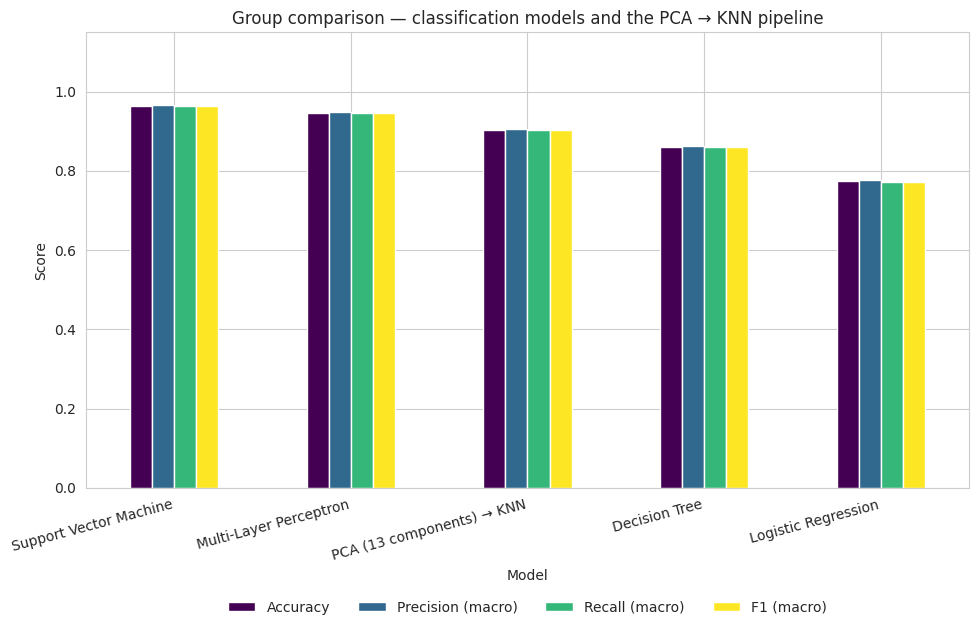

In [3]:
metrics_to_plot = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']
plot_df = head_to_head.set_index('Model')[metrics_to_plot]

ax = plot_df.plot(kind='bar', figsize=(10, 6.5), colormap='viridis')
ax.set_ylabel('Score')
ax.set_title('Group comparison — classification models and the PCA \u2192 KNN pipeline')
ax.set_ylim(0, 1.15)
plt.xticks(rotation=15, ha='right')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False)
plt.tight_layout()
plt.savefig('../results/eda_visualizations/group_classification_comparison.png', dpi=110, bbox_inches='tight')
plt.show()


## 2. Where PCA and K-Means Fit In

K-Means and PCA solve fundamentally different problems from the classifiers, so they cannot be
ranked on accuracy. They are reported on their own native metrics, alongside how each relates back
to the classification task.

In [4]:
print("--- Almeida K.K.O. — K-Means (Clustering) ---")
print(f"  Clusters chosen (k): {kmeans['k_chosen']}")
print(f"  Adjusted Rand Index vs. true letters:  {kmeans['ari_vs_true_letters']:.4f}")
print(f"  Normalized Mutual Information:         {kmeans['nmi_vs_true_letters']:.4f}")
print(f"  Silhouette-preferred k: {kmeans['silhouette_preferred_k']} "
      f"(silhouette={kmeans['silhouette_at_preferred_k']:.4f})")
print(f"  Note: ARI/NMI sit on a different 0-1 scale from accuracy and are not directly")
print(f"        comparable to it, but both are far above 0 (random) and far below the")
print(f"        weakest supervised classifier ({comparison_df['Accuracy'].min():.4f}),")
print(f"        confirming that unsupervised clustering only partially solves this task.")

print()
print("--- Danishiyan G.J. — PCA (Dimensionality Reduction) ---")
print(f"  Components kept: {pca['n_components_chosen']} of {pca['n_components_total']} "
      f"({pca['dimensionality_reduction_pct']}% fewer dimensions)")
print(f"  Variance explained: {pca['variance_explained']:.4f}")
print(f"  Downstream KNN accuracy, full features: {pca['knn_accuracy_full_features']:.4f}")
print(f"  Downstream KNN accuracy, PCA features:  {pca['knn_accuracy_pca_features']:.4f}")
print(f"  Accuracy cost of the compression: {pca['accuracy_cost_pct_points']:.2f} percentage points")


--- Almeida K.K.O. — K-Means (Clustering) ---
  Clusters chosen (k): 26
  Adjusted Rand Index vs. true letters:  0.1507
  Normalized Mutual Information:         0.3638
  Silhouette-preferred k: 20 (silhouette=0.1411)
  Note: ARI/NMI sit on a different 0-1 scale from accuracy and are not directly
        comparable to it, but both are far above 0 (random) and far below the
        weakest supervised classifier (0.7732),
        confirming that unsupervised clustering only partially solves this task.

--- Danishiyan G.J. — PCA (Dimensionality Reduction) ---
  Components kept: 13 of 21 (38.1% fewer dimensions)
  Variance explained: 0.9518
  Downstream KNN accuracy, full features: 0.9178
  Downstream KNN accuracy, PCA features:  0.9033
  Accuracy cost of the compression: 1.45 percentage points


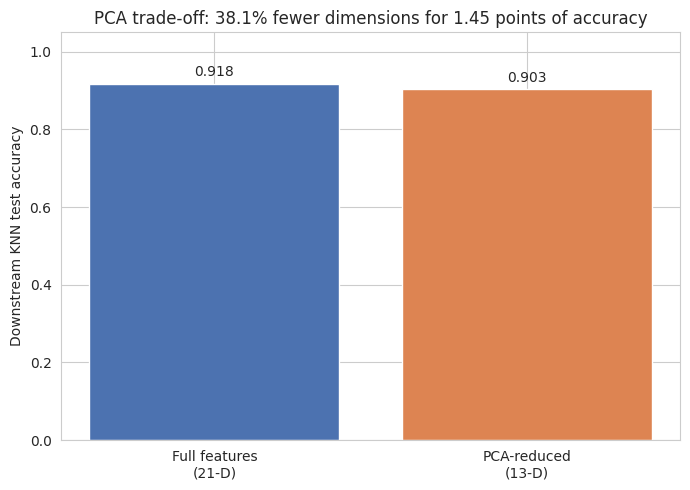

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
labels = [f"Full features\n({pca['n_components_total']}-D)",
          f"PCA-reduced\n({pca['n_components_chosen']}-D)"]
values = [pca['knn_accuracy_full_features'], pca['knn_accuracy_pca_features']]
bars = ax.bar(labels, values, color=['#4C72B0', '#DD8452'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Downstream KNN test accuracy')
ax.set_title(f"PCA trade-off: {pca['dimensionality_reduction_pct']}% fewer dimensions "
             f"for {pca['accuracy_cost_pct_points']:.2f} points of accuracy")
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.3f}", ha='center')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/group_pca_tradeoff.png', dpi=110, bbox_inches='tight')
plt.show()


## 3. Expected versus Observed Behaviour

**What the group expected, as set out in each member's Section 1:**

- Linear methods (Logistic Regression) would trail non-linear methods (SVM, MLP, Decision Tree),
  because letter-shape classes overlap in ways a straight boundary cannot separate.
- K-Means would recover some coarse letter-family structure but nothing close to supervised
  accuracy, since Euclidean spheres are a poor match for 26 visually overlapping shapes.
- PCA would reveal meaningful redundancy among the 21 features, since five of them were engineered
  from the other sixteen.

**What was actually observed:**

In [6]:
best_row = comparison_df.iloc[0]
worst_row = comparison_df.iloc[-1]

print(f"Strongest classifier: {best_row['Model']} ({best_row['Member']}) "
      f"— accuracy {best_row['Accuracy']:.4f}")
print(f"Weakest classifier:   {worst_row['Model']} ({worst_row['Member']}) "
      f"— accuracy {worst_row['Accuracy']:.4f}")
print(f"Spread across the four classifiers: "
      f"{(best_row['Accuracy'] - worst_row['Accuracy'])*100:.2f} percentage points")
print()
print(f"The {(best_row['Accuracy'] - worst_row['Accuracy'])*100:.1f}-point gap between the best "
      f"non-linear model and the linear baseline is direct evidence that this dataset's class\n"
      f"boundaries are non-linear — confirming the group's first expectation.")
print()
print(f"K-Means: ARI {kmeans['ari_vs_true_letters']:.4f} / NMI {kmeans['nmi_vs_true_letters']:.4f} "
      f"— above random but far below supervised performance, confirming the second expectation.")
print()
print(f"PCA: {pca['variance_explained']*100:.1f}% of variance retained in "
      f"{pca['n_components_chosen']} of {pca['n_components_total']} dimensions, at a cost of "
      f"{pca['accuracy_cost_pct_points']:.2f} accuracy points\n"
      f"— confirming real but not cost-free redundancy, the third expectation.")


Strongest classifier: Support Vector Machine (Nirushiya A.) — accuracy 0.9646
Weakest classifier:   Logistic Regression (Wijayagunasekara L.A.V.D.S.) — accuracy 0.7732
Spread across the four classifiers: 19.15 percentage points

The 19.1-point gap between the best non-linear model and the linear baseline is direct evidence that this dataset's class
boundaries are non-linear — confirming the group's first expectation.

K-Means: ARI 0.1507 / NMI 0.3638 — above random but far below supervised performance, confirming the second expectation.

PCA: 95.2% of variance retained in 13 of 21 dimensions, at a cost of 1.45 accuracy points
— confirming real but not cost-free redundancy, the third expectation.


## 4. Challenges Encountered

- **A latent data-quality defect in the engineered features.** Three of the five engineered
  features are ratios, and a small number of rows have a denominator of exactly zero. An initial
  implementation guarded this by adding a tiny epsilon before dividing, which does not actually
  prevent the blow-up — it converts division by zero into division by a near-zero number, producing
  values in the hundreds of thousands. These extreme values distorted standardisation and the
  principal components downstream. The fix was to floor each denominator at 1, which bounds every
  ratio to a sensible range. All results in this phase use the corrected dataset.
- **Compute budget.** Grid searches had to be kept modest — particularly for the SVM, whose
  training cost grows roughly quadratically with sample count, and the MLP, where each of the 16
  architectures is trained three times under cross-validation.
- **Comparing unlike models fairly.** Accuracy is undefined for clustering and dimensionality
  reduction, so a single ranked league table across all six models would have been misleading. The
  group instead reports each model on metrics appropriate to its task type and compares only
  like with like.

## 5. Group Conclusion

In [7]:
# Final group summary: one row per member, with each model's main result in its own native metric.
TYPE = {'Support Vector Machine': 'Classification',
        'Multi-Layer Perceptron': 'Deep Learning (Classification)',
        'Decision Tree': 'Classification',
        'Logistic Regression': 'Classification'}

summary = comparison_df[['Model', 'Member', 'Accuracy', 'Precision (macro)',
                         'Recall (macro)', 'F1 (macro)']].copy()
summary['Type'] = summary['Model'].map(TYPE)
summary['Main Result'] = summary['Accuracy'].map(lambda a: f"{a*100:.2f}% test accuracy")

summary.loc[len(summary)] = {
    'Model': 'K-Means', 'Member': kmeans['member'].split(' (')[0], 'Type': 'Clustering',
    'Main Result': (f"k = {kmeans['k_chosen']}, ARI = {kmeans['ari_vs_true_letters']:.3f}, "
                    f"NMI = {kmeans['nmi_vs_true_letters']:.3f}")}
# PCA does not predict letters itself, so its row reports the metrics of the PCA -> KNN pipeline
# (KNN trained on the 13 PCA components), and the model name says so explicitly.
summary.loc[len(summary)] = {
    'Model': f"PCA ({pca['n_components_chosen']} components) \u2192 KNN", 'Member': pca['member'].split(' (')[0],
    'Type': 'Dimensionality Reduction + Classification (KNN)',
    'Accuracy': pca['knn_accuracy_pca_features'],
    'Precision (macro)': pca['knn_precision_macro_pca_features'],
    'Recall (macro)': pca['knn_recall_macro_pca_features'],
    'F1 (macro)': pca['knn_f1_macro_pca_features'],
    'Main Result': (f"{pca['n_components_total']} -> {pca['n_components_chosen']} components, "
                    f"{pca['variance_explained']*100:.2f}% variance retained, "
                    f"{pca['knn_accuracy_pca_features']*100:.2f}% downstream KNN accuracy "
                    f"(vs {pca['knn_accuracy_full_features']*100:.2f}% on all features)")}

summary = summary[['Member', 'Model', 'Type', 'Main Result', 'Accuracy',
                   'Precision (macro)', 'Recall (macro)', 'F1 (macro)']]

# Accuracy / Precision / Recall / F1 do not apply to clustering, so K-Means is marked "N/A";
# its result is in the Main Result column.
metric_cols = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']
for c in metric_cols:
    summary[c] = summary[c].map(lambda v: 'N/A' if pd.isna(v) else f"{v:.4f}")

summary.to_csv('../results/group_final_comparison.csv', index=False)
print("Saved: results/group_final_comparison.csv")
print("N/A = metric does not apply to clustering (K-Means); its result is in the Main Result column.")
print("PCA row: metrics of the PCA -> KNN pipeline (KNN trained on the PCA components). PCA itself does")
print("not predict letters, so these are KNN's metrics on the reduced features, not 'PCA accuracy'.")

pd.set_option('display.max_colwidth', None)   # show the full Main Result text, no truncation
summary


Saved: results/group_final_comparison.csv
N/A = metric does not apply to clustering (K-Means); its result is in the Main Result column.
PCA row: metrics of the PCA -> KNN pipeline (KNN trained on the PCA components). PCA itself does
not predict letters, so these are KNN's metrics on the reduced features, not 'PCA accuracy'.


,Member,Model,Type,Main Result,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Nirushiya A.,Support Vector Machine,Classification,96.46% test accuracy,0.9646,0.9654,0.9645,0.9648
1,Muhunthan R.,Multi-Layer Perceptron,Deep Learning (Classification),94.67% test accuracy,0.9467,0.9476,0.9457,0.9464
2,Thrishodaran V.,Decision Tree,Classification,86.05% test accuracy,0.8605,0.8615,0.8606,0.8607
3,Wijayagunasekara L.A.V.D.S.,Logistic Regression,Classification,77.32% test accuracy,0.7732,0.7773,0.7720,0.7730
4,Almeida K.K.O.,K-Means,Clustering,"k = 26, ARI = 0.151, NMI = 0.364",N/A,N/A,N/A,N/A
5,Danishiyan G.J.,PCA (13 components) → KNN,Dimensionality Reduction + Classification (KNN),"21 -> 13 components, 95.18% variance retained, 90.33% downstream KNN accuracy (vs 91.78% on all features)",0.9033,0.9064,0.9028,0.9037


### Danishiyan G.J. — PCA result in detail

PCA does not predict letters, so it has no accuracy of its own. Its result is measured by the
variance it retains and by the accuracy of a fixed KNN classifier trained on its output.

In [8]:
pca_table = pd.DataFrame({
    'Measure': ['Original features',
                'PCA components kept',
                'Variance retained',
                'Dimensionality reduction',
                'KNN test accuracy — all 21 features (baseline)',
                'KNN test accuracy — PCA-reduced features',
                'Accuracy difference',
                'KNN macro precision — PCA-reduced features',
                'KNN macro recall — PCA-reduced features',
                'KNN macro F1 — PCA-reduced features'],
    'Value': [f"{pca['n_components_total']}",
              f"{pca['n_components_chosen']}",
              f"{pca['variance_explained']*100:.2f}%",
              f"{pca['dimensionality_reduction_pct']}%",
              f"{pca['knn_accuracy_full_features']*100:.2f}%",
              f"{pca['knn_accuracy_pca_features']*100:.2f}%",
              f"{pca['accuracy_cost_pct_points']:.2f} percentage points",
              f"{pca['knn_precision_macro_pca_features']*100:.2f}%",
              f"{pca['knn_recall_macro_pca_features']*100:.2f}%",
              f"{pca['knn_f1_macro_pca_features']*100:.2f}%"],
})
pca_table


,Measure,Value
0,Original features,21
1,PCA components kept,13
2,Variance retained,95.18%
3,Dimensionality reduction,38.1%
4,KNN test accuracy — all 21 features (baseline),91.78%
5,KNN test accuracy — PCA-reduced features,90.33%
6,Accuracy difference,1.45 percentage points
7,KNN macro precision — PCA-reduced features,90.64%
8,KNN macro recall — PCA-reduced features,90.28%
9,KNN macro F1 — PCA-reduced features,90.37%


**Findings:**

- The two **non-linear, high-capacity models** — the tuned SVM with an RBF kernel and the tuned
  two-layer MLP — are the group's strongest classifiers. This matches both the published literature
  on this dataset and the overlapping class structure visible in the PCA projection and in every
  confusion matrix produced above.
- The **Decision Tree** sits meaningfully behind them but remains the only model whose individual
  predictions can be read as a short sequence of human-readable threshold tests. It is the right
  choice wherever explainability outweighs a few points of accuracy.
- **Logistic Regression** is the weakest classifier by a wide margin, which is the intended result:
  it establishes what a purely linear decision boundary can achieve here, and the gap above it
  quantifies how much the other models gain from non-linearity.
- **K-Means** shows that genuine but only partial letter structure exists in the feature space
  without any supervision — a useful exploratory finding rather than a competitive classifier.
- **PCA** shows the 21-feature set can be compressed by about a third while giving up a small,
  precisely measured amount of downstream accuracy, which would matter for a resource-constrained
  deployment.

**Recommendation:** for the group's stated OCR objective, the **tuned SVM** is the primary
recommended model, with the **MLP** as a close second. The Decision Tree is offered as the
interpretable alternative, and PCA as an optional compression step where memory or latency is
constrained.

**Group-level limitations:**

- Every model was tuned with 3-fold cross-validation and evaluated on a single held-out test split.
  A full nested cross-validation across all six models would give a statistically firmer comparison.
- Hyperparameter grids were deliberately modest for compute reasons; a randomised or Bayesian search
  over a wider space could plausibly improve the SVM and MLP further.
- No convolutional network was attempted, because this dataset provides pre-extracted statistical
  descriptors rather than raw character images — a CNN would only be appropriate with the original
  pixel data.